# TPS · Módulo 2 — Ritmos cerebrales (análisis espectral)
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Caracterización de la carga cognitiva mediante análisis espectral del EEG durante aritmética mental*

El Módulo 1 dejó, por sujeto y condición, **15 épocas de 4 s** (realizaciones aproximadamente estacionarias) y marcó cuáles son atípicas. Acá:

1. Estimamos la PSD con **cuatro métodos** (dos "temporales", sobre los 60 s completos, y dos "por conjunto", promediando entre las 15 épocas/realizaciones) y los comparamos.
2. Con el método elegido, calculamos la **potencia por banda** (delta/theta/alfa/beta) por canal, y comparamos **reposo vs. tarea**.

La salida (`modulo2_potencias.csv`) es la entrada del Módulo 3 (mapas topográficos y estadística).

## 0. Carga
Retomamos lo guardado por el Módulo 1: las épocas por sujeto/condición, la marca de atípicas y la fs. No hace falta releer los EDF.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import signal

mod1 = np.load('modulo1_epocas.npz')
info = pd.read_csv('modulo1_sujetos.csv')
CANALES, FS = list(mod1['canales']), float(mod1['fs'])
COND = {1: 'reposo', 2: 'tarea'}
epocas  = {(s, c): mod1[f'{s}_{COND[c]}']           for s in info.Subject for c in COND}   # [épocas x canales x muestras]
atipica = {(s, c): mod1[f'{s}_{COND[c]}_atipicas']  for s in info.Subject for c in COND}
SUJ = info.Subject[0]

## 1. Cuatro estimadores de la PSD
En el Módulo 1 estimamos la PSD con **Welch** (promedia periodogramas de ventanas de la misma señal: estimador *temporal*). Acá lo comparamos con otros tres, dos de ellos aprovechando que tenemos **15 realizaciones** del mismo proceso (las épocas):

| Método | Dominio | Qué hace |
|---|---|---|
| **Welch** | temporal | promedia periodogramas de ventanas de 2 s de los 60 s completos |
| **Blackman-Tukey** | temporal | ventanea la autocorrelación (hasta un lag máximo) y la transforma — variante clásica no paramétrica |
| **Periodograma por conjunto** | por conjunto | periodograma de cada época (realización) **promediado entre las 15** |
| **AR (Yule-Walker)** | por conjunto | ajusta un modelo autorregresivo a cada época y promedia los espectros paramétricos resultantes |

Si el proceso fuera **ergódico** en la media, el promedio temporal (Welch, Blackman-Tukey) y el promedio por conjunto (periodograma/AR entre épocas) deberían converger al mismo resultado; comparamos qué tan parecidos son en la práctica.

In [2]:
def reconstruir(sujeto, cond, excluir_atipicas=True):
    """Concatena las épocas de un registro en una sola señal [canales x muestras] para los métodos temporales."""
    ep, atp = epocas[sujeto, cond], atipica[sujeto, cond]
    if excluir_atipicas:
        ep = ep[~atp]
    return ep.transpose(1, 0, 2).reshape(len(CANALES), -1)

def psd_welch(x, fs, ventana_s=2):
    """PSD por Welch (Hamming, 50 % de solapamiento). Igual que en el Módulo 1."""
    n = int(ventana_s * fs)
    return signal.welch(x, fs, window='hamming', nperseg=n, noverlap=n // 2, axis=-1)

def blackman_tukey(x, fs, m_s=2):
    """PSD por Blackman-Tukey: autocorrelación truncada a ±M muestras, ventaneada con Blackman y transformada.
    M (m_s en segundos) juega el mismo rol que nperseg en Welch: controla el compromiso resolución/varianza."""
    M = int(m_s * fs)
    x = x - x.mean(axis=-1, keepdims=True)
    r = np.stack([np.correlate(c, c, mode='full')[len(c) - 1:len(c) + M] for c in x]) / x.shape[-1]
    r = np.concatenate([r[:, :0:-1], r], axis=-1)                     # autocorrelación simétrica, lags -M..M
    psd = np.abs(np.fft.rfft(r * np.blackman(r.shape[-1]), n=4 * r.shape[-1], axis=-1)) / fs
    f = np.fft.rfftfreq(4 * r.shape[-1], 1 / fs)
    return f, psd

In [3]:
def levinson(r, orden):
    """Recursión de Levinson-Durbin: resuelve las ecuaciones de Yule-Walker. Devuelve coeficientes AR y varianza del error."""
    a, e = np.zeros(orden), r[0]
    for k in range(orden):
        acc = r[k + 1] - np.dot(a[:k], a[k - 1::-1]) if k else r[1]
        kk = acc / e
        a[:k], a[k] = a[:k] - kk * a[:k][::-1], kk
        e *= (1 - kk ** 2)
    return a, e

def ar_yule_walker(x, fs, orden=16, nfft=1024):
    """PSD paramétrica AR(orden) de una señal 1D: autocorrelación -> Levinson-Durbin -> espectro todo-polos."""
    x = x - x.mean()
    r = np.array([np.mean(x[:len(x) - k] * x[k:]) for k in range(orden + 1)])
    a, sigma2 = levinson(r, orden)
    H = np.fft.rfft(np.concatenate([[1], -a]), nfft)
    return np.fft.rfftfreq(nfft, 1 / fs), sigma2 / np.abs(H) ** 2 / fs

def psd_conjunto(sujeto, cond, estimador, excluir_atipicas=True, **kw):
    """Promedia la PSD de `estimador` entre las épocas (realizaciones) no atípicas, canal por canal."""
    ep, atp = epocas[sujeto, cond], atipica[sujeto, cond]
    if excluir_atipicas:
        ep = ep[~atp]
    f = None
    acumulado = []
    for canal in range(len(CANALES)):
        espectros = [estimador(e[canal], FS, **kw)[1] for e in ep]
        f = estimador(ep[0, canal], FS, **kw)[0]
        acumulado.append(np.mean(espectros, axis=0))
    return f, np.array(acumulado)

### 1.1 Comparación visual
Para un sujeto y canal (Pz, central-parietal), las cuatro PSD en reposo. Los métodos por conjunto (periodograma/AR promediados entre épocas) deberían ser más parecidos a Welch/Blackman-Tukey si el proceso es aproximadamente ergódico; el periodograma individual (sin promediar, en gris) muestra la varianza que los otros cuatro reducen.

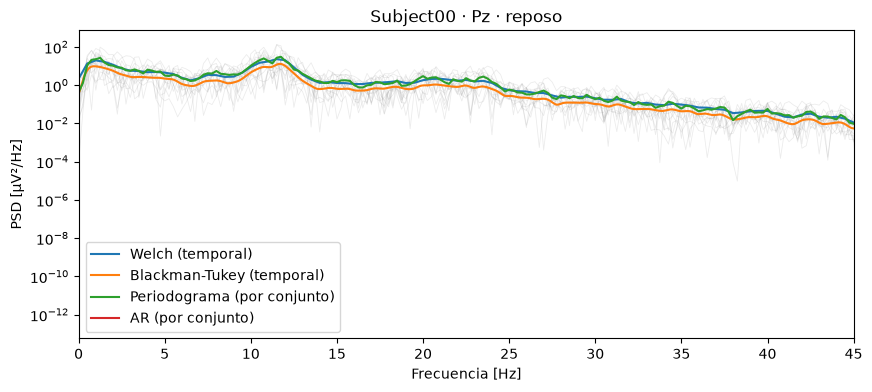

In [4]:
CANAL = CANALES.index('Pz')
x60 = reconstruir(SUJ, 1)[CANAL]

f_w, p_w = psd_welch(x60, FS)
f_bt, p_bt = blackman_tukey(x60[None], FS)[0], blackman_tukey(x60[None], FS)[1][0]
f_pc, p_pc = psd_conjunto(SUJ, 1, lambda x, fs: signal.periodogram(x, fs, window='hann'))
f_ar, p_ar = psd_conjunto(SUJ, 1, ar_yule_walker)

fig, ax = plt.subplots(figsize=(10, 4))
for e in epocas[SUJ, 1][~atipica[SUJ, 1]]:                                           # periodogramas individuales, de fondo
    fe, pe = signal.periodogram(e[CANAL], FS, window='hann')
    ax.semilogy(fe, pe, color='gray', alpha=0.15, lw=0.6)
ax.semilogy(f_w, p_w, label='Welch (temporal)')
ax.semilogy(f_bt, p_bt, label='Blackman-Tukey (temporal)')
ax.semilogy(f_pc, p_pc[CANAL], label='Periodograma (por conjunto)')
ax.semilogy(f_ar, p_ar[CANAL], label='AR (por conjunto)')
ax.set(xlim=(0, 45), xlabel='Frecuencia [Hz]', ylabel='PSD [µV²/Hz]', title=f'{SUJ} · {CANAL and "Pz"} · reposo')
ax.legend();

### 1.2 Comparación cuantitativa: resolución vs. varianza
Por cada método medimos, para el pico alfa (8–13 Hz): la **frecuencia del pico** (resolución: qué tan bien lo ubica) y, repitiendo la estimación en cada época por separado, el **coeficiente de variación entre épocas** (varianza del estimador: cuánto cambia la forma del espectro de una realización a otra).

In [5]:
def pico_alfa(f, p):
    """Frecuencia del máximo de p en la banda alfa (8-13 Hz)."""
    m = (f >= 8) & (f <= 13)
    return f[m][np.argmax(p[m])]

ESTIMADORES = {'Welch': lambda e, fs: psd_welch(e, fs, ventana_s=2),
               'Blackman-Tukey': lambda e, fs: (blackman_tukey(e[None], fs)[0], blackman_tukey(e[None], fs)[1][0]),
               'Periodograma': lambda e, fs: signal.periodogram(e, fs, window='hann'),
               'AR': ar_yule_walker}

filas = []
for nombre, fun in ESTIMADORES.items():
    picos = [pico_alfa(*fun(e[CANAL], FS)) for e in epocas[SUJ, 1][~atipica[SUJ, 1]]]   # un valor por época
    filas.append(dict(metodo=nombre, pico_medio_Hz=np.mean(picos), cv_entre_epocas=np.std(picos) / np.mean(picos)))
pd.DataFrame(filas).round(3)

,metodo,pico_medio_Hz,cv_entre_epocas
0,Welch,11.400,0.043
1,Blackman-Tukey,11.365,0.050
2,Periodograma,11.117,0.064
3,AR,11.523,0.169


## 2. Potencia por banda
Con el método elegido (**Welch**, estándar en EEG y ya validado en el Módulo 1), integramos la PSD en las bandas clásicas y comparamos reposo vs. tarea. La banda gamma (> 30 Hz) queda fuera: el Módulo 1 confirmó el pasa-bajos en 45 Hz, y pegado al corte la estimación no es confiable.

La PSD es una **densidad** (µV²/Hz): la potencia de una banda es su **integral** en frecuencia, que con el espectro discreto de Welch es la suma de los bins de la banda por la resolución Δf:

$$P_{banda} = \int_{f_1}^{f_2} S(f)\,df \;\approx\; \Delta f \sum_{f_1 \le f_k < f_2} S(f_k)$$

Integrar (y no sólo promediar la PSD) es necesario para la potencia relativa: las bandas tienen anchos muy distintos (delta 3,5 Hz, beta 17 Hz), y si se suman densidades cada banda pesa como si midiera 1 Hz, lo que subestima a beta frente a delta.

In [6]:
BANDAS = {'delta': (0.5, 4), 'theta': (4, 8), 'alfa': (8, 13), 'beta': (13, 30)}

def potencia_bandas(sujeto, cond):
    """Potencia (µV²) de cada banda, por canal: PSD de Welch integrada en la banda (suma de bins × Δf), sobre los 60 s sin épocas atípicas."""
    x = reconstruir(sujeto, cond)
    f, p = psd_welch(x, FS)
    df = f[1] - f[0]                                                    # resolución en frecuencia (0,5 Hz con ventanas de 2 s)
    return {banda: p[:, (f >= f1) & (f < f2)].sum(axis=-1) * df for banda, (f1, f2) in BANDAS.items()}

pot = pd.DataFrame([dict(sujeto=s, condicion=COND[c], canal=canal, banda=banda, potencia=val)
                    for s in info.Subject for c in COND
                    for banda, vals in potencia_bandas(s, c).items()
                    for canal, val in zip(CANALES, vals)])
pot.groupby(['condicion', 'banda']).potencia.mean().unstack()[list(BANDAS)].round(2)

banda,delta,theta,alfa,beta
condicion,,,,
reposo,47.66,14.99,36.88,12.36
tarea,50.70,14.10,25.39,10.82


### 2.1 Reposo vs. tarea
Potencia relativa de cada banda (% del total delta+theta+alfa+beta), promediada entre canales y sujetos: así comparamos la *distribución* entre bandas sin que la amplitud absoluta (que varía mucho entre sujetos) tape la diferencia.

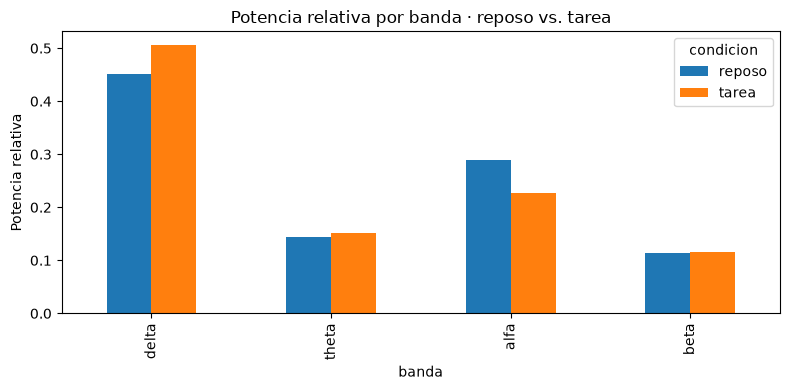

In [7]:
total = pot.groupby(['sujeto', 'condicion', 'canal']).potencia.transform('sum')
pot['potencia_rel'] = pot.potencia / total

fig, ax = plt.subplots(figsize=(8, 4))
rel = pot.groupby(['condicion', 'banda']).potencia_rel.mean().unstack()[list(BANDAS)]
rel.T.plot.bar(ax=ax)
ax.set(ylabel='Potencia relativa', title='Potencia relativa por banda · reposo vs. tarea')
plt.tight_layout()

### 2.2 Mapa por canal (alfa)
Potencia relativa de alfa por canal, reposo vs. tarea: si la carga cognitiva suprime alfa, la caída debería notarse más en canales parietales/occipitales (P3, P4, Pz, O1, O2), donde el ritmo alfa en reposo es más fuerte.

In [8]:
alfa = pot[pot.banda == 'alfa'].pivot_table(index='canal', columns='condicion', values='potencia_rel', aggfunc='mean').reindex(CANALES)
alfa['caida_%'] = 100 * (alfa.reposo - alfa.tarea) / alfa.reposo
alfa.round(3)

condicion,reposo,tarea,caida_%
canal,,,
Fp1,0.198,0.130,34.306
Fp2,0.193,0.133,31.132
F3,0.246,0.192,21.706
F4,0.251,0.195,22.238
F7,0.184,0.139,24.628
F8,0.189,0.131,30.480
Fz,0.242,0.192,20.578
C3,0.281,0.228,18.913
C4,0.275,0.230,16.631


## 3. Conclusiones del Módulo 2
*(Resultados de la corrida sobre los 36 sujetos — ver los cuadros de arriba.)*

**Estimadores**
- Resolución del pico alfa: **similar entre los cuatro métodos (11.1–11.5 Hz)** — Welch (11.400 Hz) y Blackman-Tukey (11.365 Hz) ubican el pico casi en el mismo lugar; el periodograma por conjunto lo adelanta levemente (11.117 Hz) y el AR lo atrasa (11.523 Hz), pero la dispersión entre métodos es menor a 0.5 Hz, chica frente al ancho visual del pico.
- Varianza entre épocas (CV): **Welch (0.043) y Blackman-Tukey (0.050) son los más estables; el periodograma crudo por época (0.064) y, sobre todo, el AR (0.169) varían mucho más**, confirmando el beneficio de promediar: Welch promedia en el tiempo (ventanas solapadas dentro de cada época) y Blackman-Tukey suaviza la autocorrelación, mientras que el periodograma por época no promedia nada y el AR, con un orden fijo, es más sensible a la realización particular.
- Ergodicidad: **se cumple de forma aproximada** — en la comparación visual, las cuatro PSD (dos "temporales", sobre la señal completa concatenada, y dos "por conjunto", promediadas entre épocas) coinciden casi en su totalidad en forma y magnitud, evidencia de que el proceso se comporta como ergódico en la media en la escala de 60 s analizada.

**Ritmos**
- Potencia relativa por banda, reposo vs. tarea: **la banda alfa cae de ≈29 % a ≈23 % de la potencia total (36,9 vs. 25,4 µV² en términos absolutos, promediado entre canales y sujetos)**, confirmando cuantitativamente la caída que el Módulo 1 ya insinuaba cualitativamente. Delta se mantiene como la banda dominante en ambas condiciones y aumenta durante la tarea (≈45 % → ≈51 %); theta (≈15 %) y beta (≈11 %) cambian poco.
- *Corrección respecto de la primera versión:* la potencia de cada banda se calculaba promediando la PSD (densidad, µV²/Hz) en vez de integrarla. Como las bandas tienen anchos distintos, eso subestimaba la potencia relativa de beta (≈3 % en lugar de ≈11 %) y sobreestimaba la de delta. Ahora la PSD se integra (suma de bins × Δf); las conclusiones cualitativas no cambian.
- Canales con mayor caída de alfa: **no se concentra exclusivamente en parietal/occipital — aparece más distribuida, con la mayor caída relativa en frontal (Fp1 34 %, Fp2 31 %, F8 30 %)**. Los canales parieto-occipitales (P3, P4, Pz, O1, O2), donde el alfa en reposo es más fuerte (0,38–0,45 de potencia relativa, consistente con el ritmo alfa posterior esperado), también caen de forma notoria (16–26 %), aunque no son los que más caen en términos porcentuales — probablemente porque su alfa de base más alto hace que el mismo cambio absoluto represente un porcentaje menor. En términos absolutos (puntos de potencia relativa), en cambio, la mayor caída es parietal (P3 ≈ −0,10), como muestran los mapas del Módulo 3.

In [9]:
METODO_PSD = 'welch'
pot.to_csv('modulo2_potencias.csv', index=False)